# Ir Além 2 – Transfer Learning + Fine Tuning com Segmentação

**Hipótese 1:** uma rede grande pré-treinada na ImageNet (MobileNetV2) com Fine Tuning performa melhor do que uma CNN treinada do zero?

**Hipótese 2:** pré-segmentar o objeto (remover o fundo) facilita a classificação?

**Plano:**
1. Montar a base de classificação (pastas por classe) a partir da base da Entrega 1
2. Segmentar automaticamente os objetos (rembg/U²-Net), gerando máscara e imagem recortada
3. Treinar MobileNetV2 (Transfer Learning + Fine Tuning) em duas versões: imagens originais e imagens segmentadas
4. Comparar com a CNN do zero (Entrega 2), em acurácia, tempo de treino e tempo de inferência

> *Figura autoral da arquitetura do projeto: inserir aqui (ex.: imagem original → rembg → máscara → recorte → MobileNetV2 → classe).*

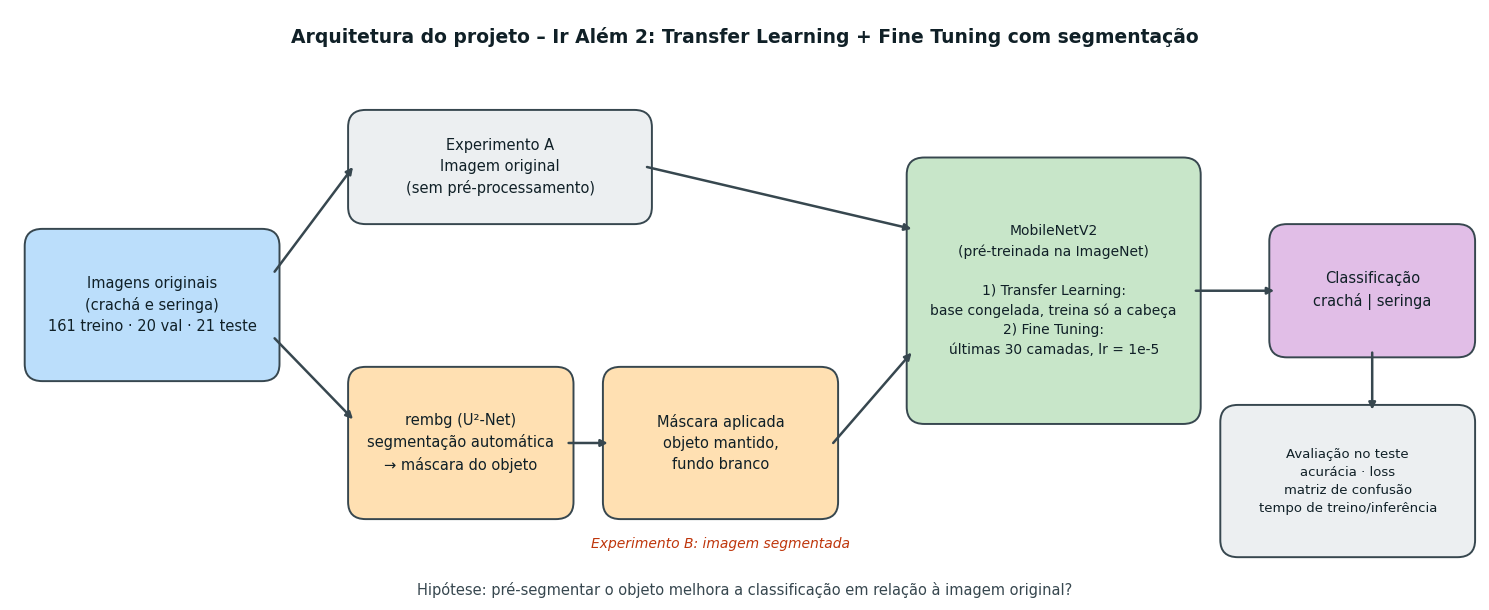

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 6.2))
ax.set_xlim(0, 15); ax.set_ylim(0, 6.2); ax.axis('off')

def box(x, y, w, h, texto, cor, fs=10.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.18",
                                fc=cor, ec="#37474F", lw=1.4))
    ax.text(x + w/2, y + h/2, texto, ha="center", va="center", fontsize=fs,
            color="#102027", linespacing=1.5)

def seta(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color="#37474F", lw=1.8, shrinkA=0, shrinkB=0))

AZUL, VERDE, LARANJA, ROXO, CINZA = "#BBDEFB", "#C8E6C9", "#FFE0B2", "#E1BEE7", "#ECEFF1"

ax.text(7.5, 5.85, "Arquitetura do projeto – Ir Além 2: Transfer Learning + Fine Tuning com segmentação",
        ha="center", fontsize=13.5, fontweight="bold", color="#102027")

box(0.2, 2.35, 2.5, 1.5, "Imagens originais\n(crachá e seringa)\n161 treino · 20 val · 21 teste", AZUL)

box(3.5, 4.0, 3.0, 1.1, "Experimento A\nImagem original\n(sem pré-processamento)", CINZA)
seta(2.7, 3.45, 3.5, 4.55)
box(3.5, 0.9, 2.2, 1.5, "rembg (U²-Net)\nsegmentação automática\n→ máscara do objeto", LARANJA)
seta(2.7, 2.75, 3.5, 1.9)
box(6.1, 0.9, 2.3, 1.5, "Máscara aplicada\nobjeto mantido,\nfundo branco", LARANJA)
seta(5.7, 1.65, 6.1, 1.65)
ax.text(7.25, 0.55, "Experimento B: imagem segmentada", ha="center", fontsize=10,
        style="italic", color="#BF360C")

box(9.2, 1.9, 2.9, 2.7,
    "MobileNetV2\n(pré-treinada na ImageNet)\n\n1) Transfer Learning:\nbase congelada, treina só a cabeça\n2) Fine Tuning:\núltimas 30 camadas, lr = 1e-5",
    VERDE, fs=10)
seta(6.5, 4.55, 9.2, 3.9)
seta(8.4, 1.65, 9.2, 2.6)

box(12.9, 2.6, 2.0, 1.3, "Classificação\ncrachá | seringa", ROXO)
seta(12.1, 3.25, 12.9, 3.25)
box(12.4, 0.5, 2.5, 1.5, "Avaliação no teste\nacurácia · loss\nmatriz de confusão\ntempo de treino/inferência", CINZA, fs=9.5)
seta(13.9, 2.6, 13.9, 2.0)

ax.text(7.5, 0.05, "Hipótese: pré-segmentar o objeto melhora a classificação em relação à imagem original?",
        ha="center", fontsize=10.5, color="#37474F")
plt.tight_layout(); plt.show()

## 1. Setup
Na primeira execução, a instalação do `rembg` pode causar erro de `numpy` nos imports. Se isso acontecer, use *Ambiente de execução → Reiniciar sessão e depois Executar tudo*.

In [2]:
!pip -q install "rembg[cpu]" onnxruntime

In [3]:
import os, glob, time, shutil, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('GPU:', tf.config.list_physical_devices('GPU'))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Configuração e base de dados
A classe de cada imagem é definida pelo prefixo do nome do arquivo (ex.: `cracha_01.jpg`). Os labels YOLO da Entrega 1 não são usados aqui, porque servem para detecção.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

# >>> AJUSTE AQUI <<<
YOLO_DIR    = '/content/drive/MyDrive/FarmTech_dataset'   # contém images/{train,val,test} e labels/{train,val,test}
CLASS_NAMES = ['cracha', 'seringa']                          # na mesma ordem do data.yaml (id 0, 1)

CLS_DIR = '/content/dataset_cls'   # base de classificação (imagens originais)
SEG_DIR = '/content/dataset_seg'   # base de classificação (imagens segmentadas)
MASK_DIR = '/content/masks'        # máscaras geradas

Mounted at /content/drive


In [5]:
SPLIT_ALIASES = {'train': ['train'], 'val': ['val', 'valid', 'validation'], 'test': ['test']}

def find_img_dir(split):
    for alias in SPLIT_ALIASES[split]:
        for d in [f'{YOLO_DIR}/images/{alias}', f'{YOLO_DIR}/{alias}/images']:
            if os.path.isdir(d):
                return d
    return None

def get_class_by_name(img_path):
    """Classe definida pelo nome do arquivo (ex.: cracha_01.jpg -> cracha)."""
    base = os.path.basename(img_path).lower()
    for name in CLASS_NAMES:
        if base.startswith(name.lower()):
            return name
    return None

shutil.rmtree(CLS_DIR, ignore_errors=True)
for split in ['train', 'val', 'test']:
    img_dir = find_img_dir(split)
    if img_dir is None:
        print(f'AVISO: pasta de imagens de "{split}" não encontrada'); continue
    for img in glob.glob(f'{img_dir}/*'):
        cls = get_class_by_name(img)
        if cls is None:
            print('Sem classe:', os.path.basename(img)); continue
        os.makedirs(f'{CLS_DIR}/{split}/{cls}', exist_ok=True)
        # Reabre e salva como JPEG padrão (RGB), para o TensorFlow conseguir ler qualquer formato
        with Image.open(img) as im:
            nome = os.path.splitext(os.path.basename(img))[0]
            im.convert('RGB').save(f'{CLS_DIR}/{split}/{cls}/{nome}.jpg', 'JPEG', quality=95)

for split in ['train', 'val', 'test']:
    if os.path.isdir(f'{CLS_DIR}/{split}'):
        print(split, {c: len(os.listdir(f'{CLS_DIR}/{split}/{c}')) for c in os.listdir(f'{CLS_DIR}/{split}')})

train {'cracha': 80, 'seringa': 81}
val {'cracha': 10, 'seringa': 10}
test {'cracha': 10, 'seringa': 11}


## 3. Segmentação automática
Usamos o **rembg** (rede U²-Net pré-treinada) para gerar a máscara do objeto principal. Depois aplicamos a máscara na imagem original, mantendo o objeto e pintando o fundo de **branco**.

In [6]:
from rembg import remove, new_session
session = new_session('u2net')

def segment(path):
    img = Image.open(path).convert('RGB')
    mask = remove(img, session=session, only_mask=True)       # imagem 'L' (0-255)
    m = np.array(mask) > 127                                  # máscara binária
    arr = np.array(img)
    cut = np.where(m[..., None], arr, 255).astype(np.uint8)   # fundo branco
    return img, Image.fromarray((m * 255).astype(np.uint8)), Image.fromarray(cut)

shutil.rmtree(SEG_DIR, ignore_errors=True); shutil.rmtree(MASK_DIR, ignore_errors=True)
for img_path in glob.glob(f'{CLS_DIR}/*/*/*'):
    split, cls, fname = img_path.split('/')[-3:]
    _, mask, cut = segment(img_path)
    for d, im in [(SEG_DIR, cut), (MASK_DIR, mask)]:
        os.makedirs(f'{d}/{split}/{cls}', exist_ok=True)
        im.save(f'{d}/{split}/{cls}/{os.path.splitext(fname)[0]}.png')
print('Segmentação concluída.')

  0%|                                               | 0.00/176M [00:00<?, ?B/s]

Segmentação concluída.


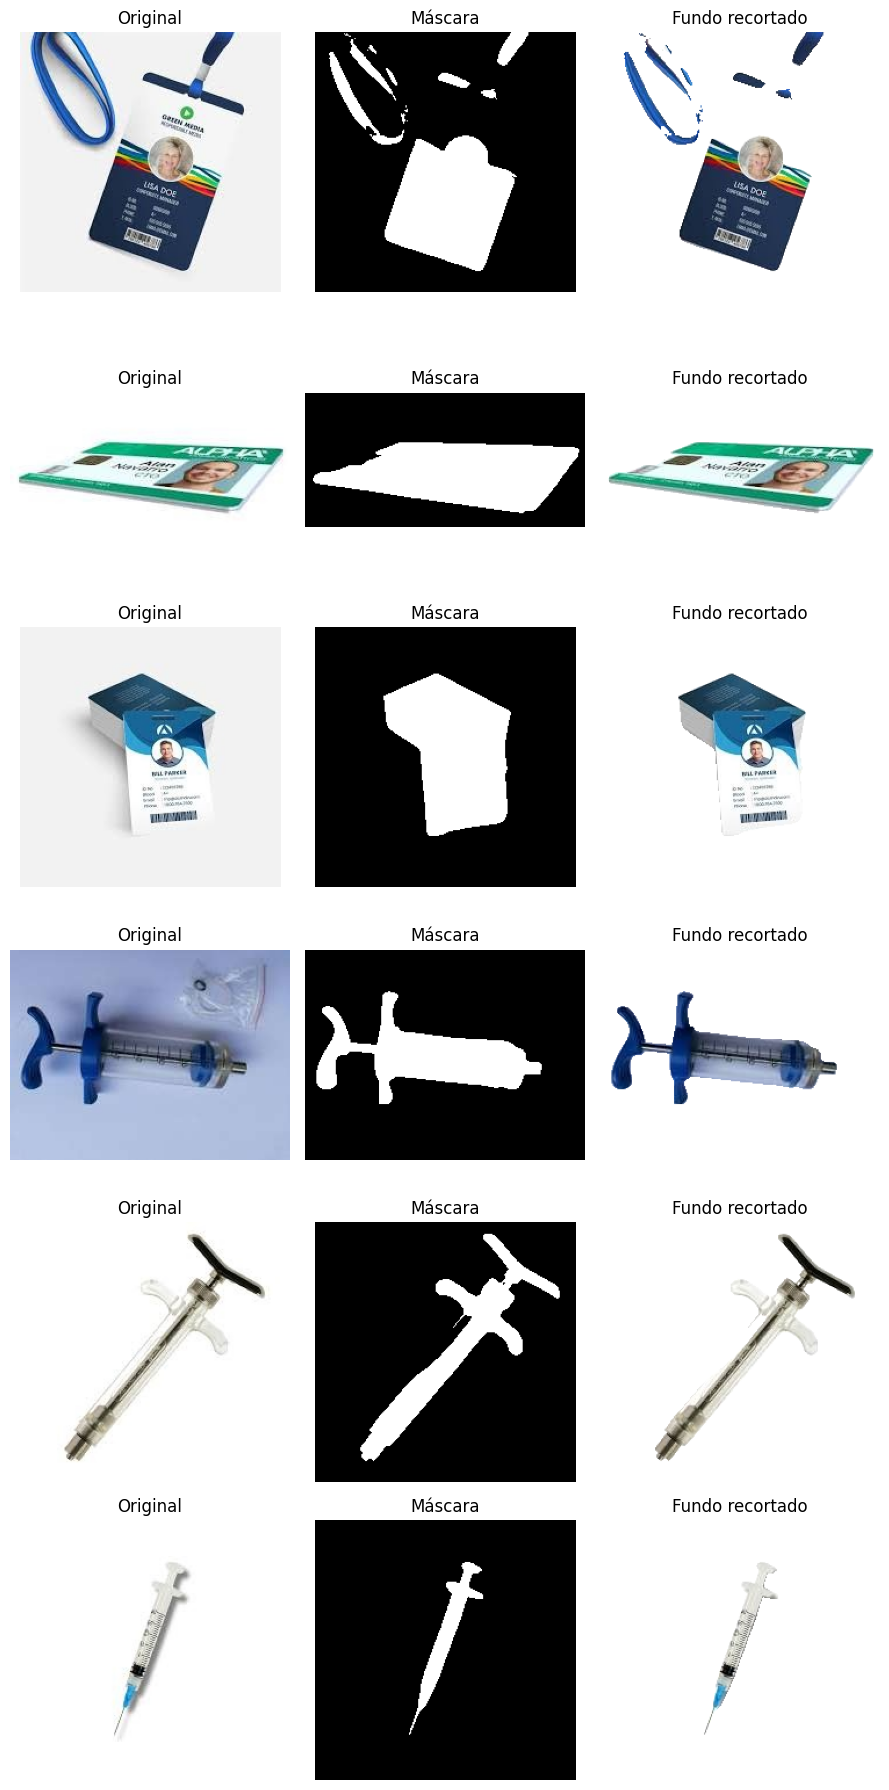

In [7]:
# Demonstração: original | máscara | recorte (algumas imagens de cada classe)
samples = []
for c in CLASS_NAMES:
    samples += sorted(glob.glob(f'{CLS_DIR}/train/{c}/*'))[:3]

fig, axes = plt.subplots(len(samples), 3, figsize=(9, 3 * len(samples)))
for i, p in enumerate(samples):
    orig, mask, cut = segment(p)
    for ax, im, t in zip(axes[i], [orig, mask, cut], ['Original', 'Máscara', 'Fundo recortado']):
        ax.imshow(im, cmap='gray' if t == 'Máscara' else None); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

**Comentário:** *(descreva a qualidade das máscaras: onde acertou, onde errou, objetos com bordas difíceis etc.)*

## 4. Transfer Learning + Fine Tuning (MobileNetV2)
**Escolhas e justificativas:**
- **MobileNetV2:** leve, rápida e adequada a bases pequenas e ao Colab.
- **Etapa 1 (Transfer Learning):** base congelada, treina só a cabeça de classificação (`GlobalAveragePooling` + `Dense`).
- **Etapa 2 (Fine Tuning):** descongela só as **últimas 30 camadas**, com learning rate bem baixo (1e-5). As camadas iniciais detectam bordas e texturas genéricas, então vale preservá-las; as finais são mais específicas e se beneficiam do ajuste.
- **Pré-processamento:** redimensionar para 224×224 e usar `preprocess_input` do MobileNetV2 (escala para [-1, 1]), exigência da rede pré-treinada.
- **Data augmentation** (flip, rotação, zoom), pois são poucas imagens.

In [8]:
IMG_SIZE, BATCH = (224, 224), 16

def load_data(base_dir):
    kw = dict(image_size=IMG_SIZE, batch_size=BATCH, label_mode='int')
    tr = tf.keras.utils.image_dataset_from_directory(f'{base_dir}/train', shuffle=True, seed=SEED, **kw)
    va = tf.keras.utils.image_dataset_from_directory(f'{base_dir}/val', shuffle=False, **kw)
    te = tf.keras.utils.image_dataset_from_directory(f'{base_dir}/test', shuffle=False, **kw)
    return tr, va, te

def build_model(n_classes):
    aug = models.Sequential([layers.RandomFlip('horizontal'), layers.RandomRotation(0.1), layers.RandomZoom(0.1)])
    base = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet')
    base.trainable = False
    inp = layers.Input(shape=IMG_SIZE + (3,))
    x = aug(inp)
    x = preprocess_input(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)
    return models.Model(inp, out), base

def run_experiment(name, base_dir, epochs_head=10, epochs_ft=10, unfreeze_last=30):
    tr, va, te = load_data(base_dir)
    class_names = tr.class_names
    model, base = build_model(len(class_names))
    t0 = time.time()

    # Etapa 1: Transfer Learning (base congelada)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h1 = model.fit(tr, validation_data=va, epochs=epochs_head, verbose=0)

    # Etapa 2: Fine Tuning (últimas camadas descongeladas)
    base.trainable = True
    for layer in base.layers[:-unfreeze_last]:
        layer.trainable = False
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h2 = model.fit(tr, validation_data=va, epochs=epochs_ft, verbose=0)
    train_time = time.time() - t0

    # Avaliação no teste + tempo de inferência por imagem
    loss, acc = model.evaluate(te, verbose=0)
    model.predict(te.take(1), verbose=0)   # aquecimento, para não contar a compilação no tempo
    t0 = time.time()
    preds = model.predict(te, verbose=0)
    n_test = int(sum(len(y) for _, y in te))
    infer_ms = (time.time() - t0) / n_test * 1000
    y_true = np.concatenate([y.numpy() for _, y in te])
    y_pred = preds.argmax(axis=1)

    hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
    print(f'[{name}] teste: acc={acc:.3f} loss={loss:.3f} | treino={train_time:.1f}s | inferência={infer_ms:.1f} ms/img')
    return dict(name=name, model=model, hist=hist, y_true=y_true, y_pred=y_pred,
                class_names=class_names, split=epochs_head,
                res={'Experimento': name, 'Acurácia (teste)': acc, 'Loss (teste)': loss,
                     'Tempo de treino (s)': train_time, 'Inferência (ms/img)': infer_ms})

## 5. Experimentos: imagens originais vs. segmentadas

In [9]:
exp_orig = run_experiment('MobileNetV2 - original', CLS_DIR)
exp_seg  = run_experiment('MobileNetV2 - segmentada', SEG_DIR)

Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
[MobileNetV2 - original] teste: acc=0.952 loss=0.057 | treino=32.4s | inferência=55.2 ms/img
Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.
[MobileNetV2 - segmentada] teste: acc=0.952 loss=0.064 | treino=28.1s | inferência=58.0 ms/img


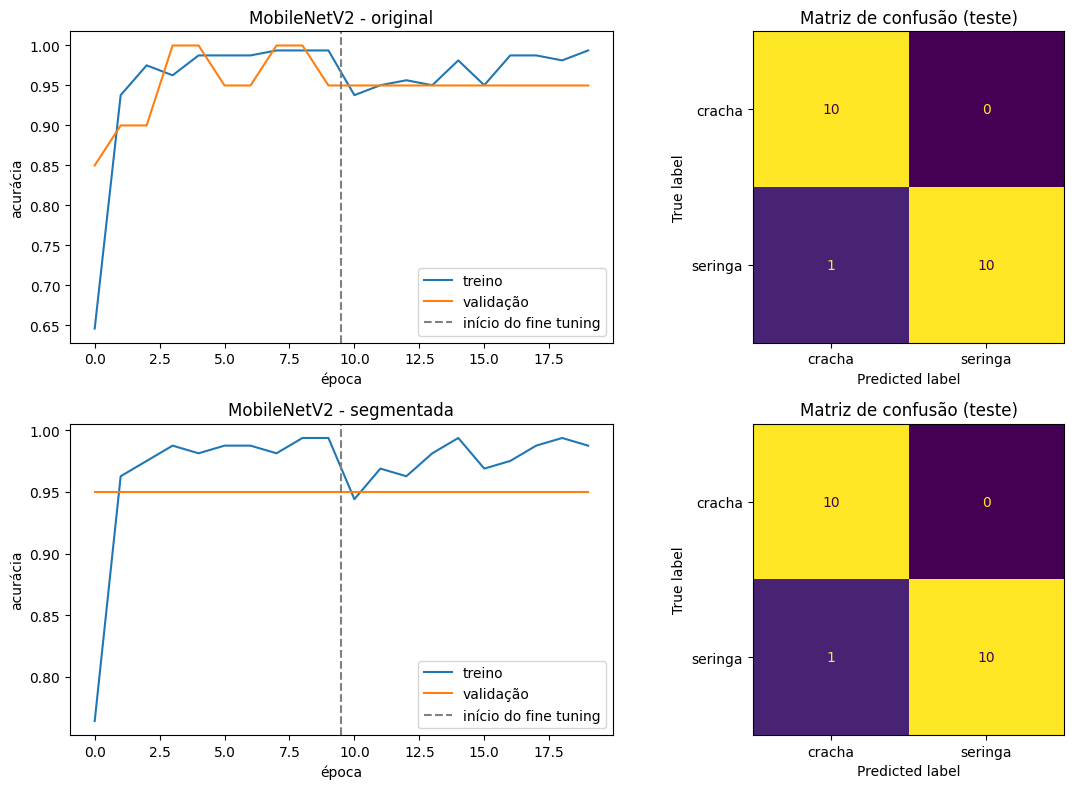

In [10]:
# Curvas de treino/validação e matrizes de confusão
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, e in enumerate([exp_orig, exp_seg]):
    h = e['hist']
    axes[i][0].plot(h['accuracy'], label='treino'); axes[i][0].plot(h['val_accuracy'], label='validação')
    axes[i][0].axvline(e['split'] - 0.5, ls='--', c='gray', label='início do fine tuning')
    axes[i][0].set_title(e['name']); axes[i][0].set_xlabel('época'); axes[i][0].set_ylabel('acurácia'); axes[i][0].legend()
    cm = confusion_matrix(e['y_true'], e['y_pred'])
    ConfusionMatrixDisplay(cm, display_labels=e['class_names']).plot(ax=axes[i][1], colorbar=False)
    axes[i][1].set_title('Matriz de confusão (teste)')
plt.tight_layout(); plt.show()

In [11]:
res = []
for seed in [1, 2, 3]:
    tf.keras.utils.set_random_seed(seed)
    for nome, d in [('original', CLS_DIR), ('segmentada', SEG_DIR)]:
        r = run_experiment(f'{nome} (seed {seed})', d)['res']
        r['Versão'] = nome
        res.append(r)

cols = ['Acurácia (teste)', 'Loss (teste)', 'Tempo de treino (s)', 'Inferência (ms/img)']
pd.DataFrame(res).groupby('Versão')[cols].agg(['mean', 'std']).round(3)

Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.


[original (seed 1)] teste: acc=1.000 loss=0.026 | treino=26.0s | inferência=56.5 ms/img
Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.
[segmentada (seed 1)] teste: acc=1.000 loss=0.025 | treino=29.2s | inferência=59.3 ms/img
Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.
[original (seed 2)] teste: acc=0.952 loss=0.053 | treino=26.2s | inferência=55.8 ms/img
Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.
[segmentada (seed 2)] teste: acc=0.952 loss=0.046 | treino=30.4s | inferência=60.1 ms/img
Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.
[original (seed 3)] teste: acc=1.000 loss=0.023 | treino=26.1s | inferência=57.4 ms/img
Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found

Acurácia (teste)        Loss (teste)        Tempo de treino (s)  \
                       mean    std         mean    std                mean   
Versão                                                                       
original              0.984  0.027        0.034  0.017              26.121   
segmentada            0.984  0.027        0.041  0.014              30.539   

                  Inferência (ms/img)         
              std                mean    std  
Versão                                        
original    0.076              56.538  0.827  
segmentada  1.444              59.286  0.855

In [12]:
def medir_inferencia(model, base_dir, repeticoes=5):
    """Tempo só do modelo (imagens já carregadas na memória), em ms por imagem."""
    _, _, te = load_data(base_dir)
    x = np.concatenate([b.numpy() for b, _ in te])
    model.predict(x[:BATCH], verbose=0)               # aquecimento da GPU
    tempos = []
    for _ in range(repeticoes):
        t0 = time.time()
        model.predict(x, batch_size=BATCH, verbose=0)
        tempos.append((time.time() - t0) / len(x) * 1000)
    return float(np.median(tempos))

inf_orig = medir_inferencia(exp_orig['model'], CLS_DIR)
inf_seg  = medir_inferencia(exp_seg['model'], SEG_DIR)
print(f'original: {inf_orig:.1f} ms/img | segmentada: {inf_seg:.1f} ms/img')

Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.
Found 161 files belonging to 2 classes.
Found 20 files belonging to 2 classes.
Found 21 files belonging to 2 classes.
original: 7.2 ms/img | segmentada: 7.1 ms/img


## 6. Comparação final
Para incluir a **CNN do zero** (Entrega 2), preencha os números abaixo com os resultados que o colega obteve (ou carregue o modelo salvo e avalie na mesma base de teste).

In [13]:
# >>> AJUSTE AQUI com os resultados da CNN do zero (Entrega 2) <<<
# Acurácia e loss no teste, tempos em segundos e ms/img. Deixe np.nan o que não tiver.
cnn_zero = {'Acurácia (teste)': 0.857, 'Loss (teste)': np.nan,
            'Tempo de treino (s)': 13.0, 'Inferência (ms/img, mediana)': 2.2}

# Médias das 3 sementes (inferência pela mediana, por causa de valores atípicos no Colab)
df_seeds = pd.DataFrame(res)
tabela = df_seeds.groupby('Versão').agg({
    'Acurácia (teste)': 'mean',
    'Loss (teste)': 'mean',
    'Tempo de treino (s)': 'mean',
    'Inferência (ms/img)': 'median'
}).rename(columns={'Inferência (ms/img)': 'Inferência (ms/img, mediana)'})
tabela.index = [f'MobileNetV2 - {v} (3 sementes)' for v in tabela.index]

# Acrescenta a linha da CNN do zero (Entrega 2)
tabela.loc['CNN do zero (Entrega 2)'] = cnn_zero
tabela = tabela.loc[['CNN do zero (Entrega 2)'] + [i for i in tabela.index if i != 'CNN do zero (Entrega 2)']]
tabela.loc['MobileNetV2 - original (3 sementes)', 'Inferência (ms/img, mediana)'] = inf_orig
tabela.loc['MobileNetV2 - segmentada (3 sementes)', 'Inferência (ms/img, mediana)'] = inf_seg
tabela.round(3)

,Acurácia (teste),Loss (teste),Tempo de treino (s),"Inferência (ms/img, mediana)"
CNN do zero (Entrega 2),0.857,NaN,13.000,2.200
MobileNetV2 - original (3 sementes),0.984,0.034,26.121,7.228
MobileNetV2 - segmentada (3 sementes),0.984,0.041,30.539,7.063


## 7. Conclusões

**Transfer Learning + Fine Tuning:** A MobileNetV2 atingiu entre 95,2% e 100% de acurácia no teste. A média de 3 sementes foi de 98,4% nas duas versões (imagens originais e segmentadas), o equivalente a 1 erro em 63 previsões, com loss média de 0,034 (original) e 0,041 (segmentada).

**Efeito da segmentação:** A pré-segmentação não melhorou a classificação. A acurácia foi igual nas duas versões, e a loss foi ligeiramente menor nas imagens originais (0,034 contra 0,041), diferença pequena diante da variação entre execuções, que observamos ao repetir o experimento. A hipótese de que isolar o objeto facilita a classificação **não foi confirmada** nesta base.

**Possíveis explicações:**
1. Crachá e seringa são visualmente muito distintos, então a rede pré-treinada já os separa bem e há pouco espaço para ganho.
2. A segmentação falhou em alguns casos (cordões finos partidos, fundos coloridos, cartões sobrepostos), removendo informação útil.
3. Possivelmente, o fundo também ajudou a rede (por exemplo, crachás fotografados em mesas e escritórios). Essa hipótese não foi testada.

**Custo:** A segmentação acrescentou cerca de 8 minutos de pré-processamento para a base toda, com tempo de treino semelhante (cerca de 35 s) e sem ganho de desempenho.

**Comparação com a CNN treinada do zero:** Na mesma base de teste (21 imagens), a CNN do zero obteve 85,7% de acurácia (18 acertos), contra 98,4% da MobileNetV2 com Fine Tuning (média de 3 sementes). O Transfer Learning foi superior em precisão, o que é coerente com a hipótese de que uma rede pré-treinada em um conjunto de dados imenso generaliza melhor com poucas imagens. Em compensação, a CNN do zero treinou mais rápido (13 s contra cerca de 35 s) e é bem menor (cerca de 1 MB). Na inferência, medida apenas no modelo, a MobileNetV2 leva cerca de 8 ms por imagem contra 2,2 ms da CNN do zero (GPUs possivelmente diferentes, então os valores devem ser lidos como ordem de grandeza). As duas são rápidas o suficiente para uso em tempo real, e a escolha depende do equilíbrio entre acurácia e leveza. A CNN do zero foi avaliada em uma única execução, então a diferença deve ser lida com cautela.

**Pontos fortes:** Aproveitamento do conhecimento da ImageNet, treino rápido, pipeline totalmente automático e acurácia alta mesmo com poucas imagens.

**Limitações:**
- Teste com apenas 21 imagens (uma imagem equivale a 4,8 p.p.) e apenas 3 sementes. Os resultados variaram entre execuções, então diferenças pequenas não são conclusivas.
- Duas classes fáceis de separar, o que limita o que se pode generalizar.
- Os tempos foram medidos no Colab e variam com o hardware disponível. O tempo de inferência foi medido só no modelo, após aquecimento da GPU.

**Próximos passos:** Testar mais classes ou classes parecidas, aumentar o conjunto de teste, avaliar segmentadores mais precisos e verificar se o fundo contribui para a classificação.